# 05 — XGBoost Churn Model (M5)
**Project:** Customer Churn Analytics & Prediction (Telco dataset)  
**Owner:** Aadrikaa  **Output files:** `05_xgboost.ipynb` + `xgboost.pkl`

**Goal:** train an XGBoost classifier on exactly the same data, features, train/test split and preprocessing as the Logistic Regression baseline (M3), tune a small number of parameters, and report Accuracy, Precision, Recall, F1 and ROC-AUC so M6 can compare all three models fairly.

**Execution order:** run the cells top to bottom (Kernel → Restart & Run All). Runtime is about a minute on a normal laptop; no GPU is needed.

**Fairness rules kept from M3:**
- same file: `telco_with_ids.csv` (M2 output)
- same target: `ChurnFlag` (1 = churned)
- same dropped columns: `customerID`, `Churn`, `tenure_group`, `charges_group`, `ChurnFlag`
- same split: `test_size=0.20`, `random_state=42`, `stratify=y`
- same preprocessing pipeline (imputer + one-hot encoding)
- tuning uses cross-validation on the **training set only**; the test set is touched once, for final evaluation

In [1]:
import os, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import xgboost as xgb
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report, roc_curve)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42          # one seed everywhere, documented for reproducibility
sns.set_theme(style="whitegrid")
print("xgboost version:", xgb.__version__)

xgboost version: 3.4.1


## 1. Load the data (same file as the Logistic Regression notebook)

In [2]:
# Looks for the M2 output next to this notebook, in the project folders, or in Drive-style folders.
CANDIDATES = [
    "telco_with_ids.csv",
    "../02_M2_EDA/telco_with_ids.csv",
    "02_M2_EDA/telco_with_ids.csv",
    "../data/processed/telco_with_ids.csv",
    "data/processed/telco_with_ids.csv",
]
DATA_PATH = next((p for p in CANDIDATES if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("telco_with_ids.csv not found. Put it next to this notebook or edit CANDIDATES.")

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, "| shape:", df.shape)
print("\nMissing values:", int(df.isnull().sum().sum()))
print("\nChurn distribution:")
print(df["Churn"].value_counts())
print((df["Churn"].value_counts(normalize=True) * 100).round(2).astype(str) + " %")

Loaded: telco_with_ids.csv | shape: (7043, 24)

Missing values: 0

Churn distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.46 %
Yes    26.54 %
Name: proportion, dtype: str


## 2. Features, target and the shared train/test split

In [3]:
drop_columns = ["customerID", "Churn", "tenure_group", "charges_group", "ChurnFlag"]
X = df.drop(columns=drop_columns)
y = df["ChurnFlag"].astype(int)
ids = df["customerID"]

numeric_features = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()
print("Numeric features    :", numeric_features)
print("Categorical features:", len(categorical_features), "columns")

# identical to M3: 80/20, stratified, random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)
print("\nTrain:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: %.4f  test: %.4f" % (y_train.mean(), y_test.mean()))

Numeric features    : ['tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: 16 columns

Train: (5634, 19) | Test: (1409, 19)
Churn rate  train: 0.2654  test: 0.2654


## 3. Preprocessing + class imbalance
Same `ColumnTransformer` as M3 (median imputer + scaler for numbers, most-frequent imputer + one-hot for categories). Scaling is not required by tree models but is harmless and keeps the pipeline identical.

Only ~26.5% of customers churn. M3 used `class_weight="balanced"`; the XGBoost equivalent is `scale_pos_weight = (#non-churn) / (#churn)` computed on the **training** set.

In [4]:
numeric_transformer = Pipeline([("imputer", SimpleImputer(strategy="median")),
                                ("scaler", StandardScaler())])
categorical_transformer = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_transformer, numeric_features),
                                  ("cat", categorical_transformer, categorical_features)])

neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
scale_pos_weight = neg / pos
print(f"Non-churn: {neg} | Churn: {pos} | scale_pos_weight = {scale_pos_weight:.3f}")

def make_pipeline(**params):
    clf = xgb.XGBClassifier(
        objective="binary:logistic", eval_metric="logloss", tree_method="hist",
        scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=1, **params)
    return Pipeline([("preprocessor", preprocessor), ("classifier", clf)])

Non-churn: 4139 | Churn: 1495 | scale_pos_weight = 2.769


## 4. Baseline XGBoost (default-ish settings)

In [5]:
def evaluate(model, X_eval, y_eval, threshold=0.5):
    prob = model.predict_proba(X_eval)[:, 1]
    pred = (prob >= threshold).astype(int)
    return {
        "Accuracy":  accuracy_score(y_eval, pred),
        "Precision": precision_score(y_eval, pred, zero_division=0),
        "Recall":    recall_score(y_eval, pred, zero_division=0),
        "F1-score":  f1_score(y_eval, pred, zero_division=0),
        "ROC-AUC":   roc_auc_score(y_eval, prob),
    }, pred, prob

baseline = make_pipeline(n_estimators=300, max_depth=6, learning_rate=0.1)
baseline.fit(X_train, y_train)
base_metrics, _, _ = evaluate(baseline, X_test, y_test)
print("Baseline XGBoost (untuned) on the test set:")
print(pd.Series(base_metrics).round(4).to_string())

Baseline XGBoost (untuned) on the test set:
Accuracy     0.7580
Precision    0.5353
Recall       0.6684
F1-score     0.5945
ROC-AUC      0.8217


## 5. Focused tuning (small grid, training data only)
Only four parameters are tuned, all aimed at reducing over-fitting on a small dataset:

| Parameter | Values | Why |
|---|---|---|
| `max_depth` | 2, 3, 4 | shallow trees generalise better on ~5.6k rows |
| `learning_rate` | 0.03, 0.05, 0.1 | step size per tree |
| `n_estimators` | 150, 300 | number of trees |
| `min_child_weight` | 1, 5 | minimum evidence needed to split |

The 36 combinations are scored with 5-fold stratified cross-validation on the training set using **ROC-AUC**, which does not depend on a threshold and is a sound basis for ranking churn risk.

In [6]:
param_grid = {
    "classifier__max_depth": [2, 3, 4],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__n_estimators": [150, 300],
    "classifier__min_child_weight": [1, 5],
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
grid = GridSearchCV(make_pipeline(), param_grid, scoring="roc_auc", cv=cv, n_jobs=-1, refit=True)
grid.fit(X_train, y_train)

print("Best CV ROC-AUC:", round(grid.best_score_, 4))
print("Best parameters:")
for k, v in grid.best_params_.items():
    print(f"  {k.replace('classifier__', ''):<18} {v}")

cv_table = (pd.DataFrame(grid.cv_results_)
            .loc[:, ["param_classifier__max_depth", "param_classifier__learning_rate",
                     "param_classifier__n_estimators", "param_classifier__min_child_weight",
                     "mean_test_score", "std_test_score"]]
            .rename(columns=lambda c: c.replace("param_classifier__", ""))
            .sort_values("mean_test_score", ascending=False).head(5).round(4))
cv_table

Best CV ROC-AUC: 0.8493
Best parameters:
  learning_rate      0.03
  max_depth          2
  min_child_weight   5
  n_estimators       300


,max_depth,learning_rate,n_estimators,min_child_weight,mean_test_score,std_test_score
3,2,0.03,300,5,0.8493,0.0119
1,2,0.03,300,1,0.8491,0.0120
8,4,0.03,150,1,0.8491,0.0115
10,4,0.03,150,5,0.8491,0.0110
14,2,0.05,150,5,0.8491,0.0117


## 6. Final evaluation on the held-out test set

In [7]:
best_model = grid.best_estimator_
metrics, y_pred, y_prob = evaluate(best_model, X_test, y_test)

print("TUNED XGBoost — test-set results (threshold 0.5)")
for k, v in metrics.items():
    print(f"  {k:<10}: {v:.4f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"], zero_division=0))

comparison = pd.DataFrame({"Baseline XGBoost": base_metrics, "Tuned XGBoost": metrics}).round(4)
comparison

TUNED XGBoost — test-set results (threshold 0.5)
  Accuracy  : 0.7424
  Precision : 0.5094
  Recall    : 0.7995
  F1-score  : 0.6223
  ROC-AUC   : 0.8443

Classification report:
              precision    recall  f1-score   support

    No Churn       0.91      0.72      0.80      1035
       Churn       0.51      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.76      0.71      1409
weighted avg       0.80      0.74      0.76      1409



,Baseline XGBoost,Tuned XGBoost
Accuracy,0.7580,0.7424
Precision,0.5353,0.5094
Recall,0.6684,0.7995
F1-score,0.5945,0.6223
ROC-AUC,0.8217,0.8443


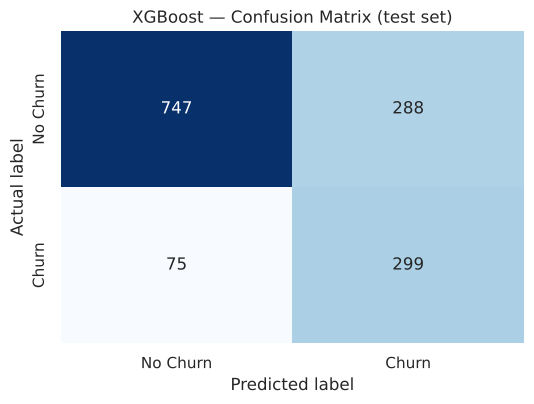

True negatives 747 | False positives 288 | False negatives 75 | True positives 299
The model catches 299 of 374 churners (79.9%); 288 loyal customers are flagged by mistake.


In [8]:
os.makedirs("figures", exist_ok=True)
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.2))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=["No Churn", "Churn"], yticklabels=["No Churn", "Churn"])
ax.set_xlabel("Predicted label"); ax.set_ylabel("Actual label")
ax.set_title("XGBoost — Confusion Matrix (test set)")
plt.tight_layout(); plt.savefig("figures/xgboost_confusion_matrix.png", dpi=150); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"True negatives {tn} | False positives {fp} | False negatives {fn} | True positives {tp}")
print(f"The model catches {tp} of {tp+fn} churners ({tp/(tp+fn):.1%}); {fp} loyal customers are flagged by mistake.")

## 7. ROC curve — with the Logistic Regression baseline on the same test set
The saved M3 `.pkl` can fail to open on a different scikit-learn version, so the baseline is **re-fitted here with M3's exact settings** (`class_weight="balanced"`, `max_iter=2000`, `random_state=42`, same split and preprocessing). It is used only for this like-for-like comparison.

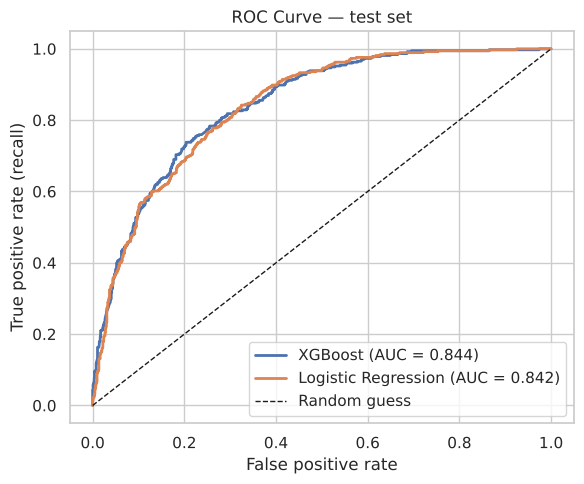

,Logistic Regression (M3 settings),XGBoost (M5)
Accuracy,0.7381,0.7424
Precision,0.5043,0.5094
Recall,0.7834,0.7995
F1-score,0.6136,0.6223
ROC-AUC,0.8415,0.8443


In [9]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

lr = Pipeline([("preprocessor", clone(preprocessor)),
               ("classifier", LogisticRegression(max_iter=2000, class_weight="balanced",
                                                 random_state=RANDOM_STATE))])
lr.fit(X_train, y_train)
lr_metrics, _, lr_prob = evaluate(lr, X_test, y_test)

fpr, tpr, _ = roc_curve(y_test, y_prob)
f2, t2, _ = roc_curve(y_test, lr_prob)
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(fpr, tpr, lw=2, label=f"XGBoost (AUC = {metrics['ROC-AUC']:.3f})")
ax.plot(f2, t2, lw=2, label=f"Logistic Regression (AUC = {lr_metrics['ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random guess")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC Curve — test set"); ax.legend(loc="lower right")
plt.tight_layout(); plt.savefig("figures/xgboost_roc_curve.png", dpi=150); plt.show()

pd.DataFrame({"Logistic Regression (M3 settings)": lr_metrics, "XGBoost (M5)": metrics}).round(4)

## 8. Feature importance (what drives churn predictions)

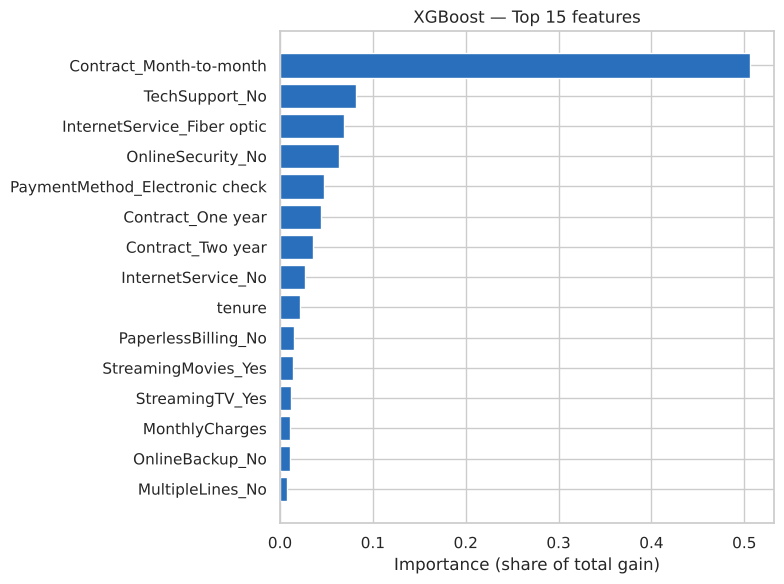

,feature,importance_gain
0,Contract_Month-to-month,0.5067
1,TechSupport_No,0.0823
2,InternetService_Fiber optic,0.0685
3,OnlineSecurity_No,0.0639
4,PaymentMethod_Electronic check,0.0470
5,Contract_One year,0.0440
6,Contract_Two year,0.0356
7,InternetService_No,0.0264
8,tenure,0.0219
9,PaperlessBilling_No,0.0148


In [10]:
pre = best_model.named_steps["preprocessor"]
clf = best_model.named_steps["classifier"]
names = pre.get_feature_names_out()
names = [n.replace("num__", "").replace("cat__", "") for n in names]

importance = (pd.DataFrame({"feature": names, "importance_gain": clf.feature_importances_})
              .sort_values("importance_gain", ascending=False).reset_index(drop=True))
top = importance.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"], top["importance_gain"], color="#2a6fbb")
ax.set_xlabel("Importance (share of total gain)")
ax.set_title("XGBoost — Top 15 features")
plt.tight_layout(); plt.savefig("figures/xgboost_feature_importance.png", dpi=150); plt.show()
importance.head(10).round(4)

## 9. Save the model, metrics and test-set predictions

In [11]:
# Whole pipeline (preprocessing + tuned XGBoost) so it can predict from raw customer columns.
joblib.dump(best_model, "xgboost.pkl")
print("Saved model: xgboost.pkl")

results = {
    "model": "XGBoost",
    "test_size": 0.20, "random_state": RANDOM_STATE, "threshold": 0.5,
    "n_train": int(len(X_train)), "n_test": int(len(X_test)),
    "best_params": {k.replace("classifier__", ""): v for k, v in grid.best_params_.items()},
    "scale_pos_weight": round(float(scale_pos_weight), 4),
    "cv_roc_auc": round(float(grid.best_score_), 4),
    "test_metrics": {k: round(float(v), 4) for k, v in metrics.items()},
    "confusion_matrix": {"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)},
}
with open("xgboost_metrics.json", "w") as f:
    json.dump(results, f, indent=2)
pd.DataFrame([{"Model": "XGBoost", **results["test_metrics"]}]).to_csv("xgboost_metrics.csv", index=False)
importance.to_csv("xgboost_feature_importance.csv", index=False)

# same rows/order as the shared test set -> M6 can join on customerID
pd.DataFrame({"customerID": ids.loc[X_test.index].values,
              "actual_churn": y_test.values,
              "xgb_predicted_churn": y_pred,
              "xgb_churn_probability": y_prob.round(6)}).to_csv("xgboost_test_predictions.csv", index=False)
print("Saved: xgboost_metrics.json / .csv, xgboost_feature_importance.csv, xgboost_test_predictions.csv, figures/*.png")

Saved model: xgboost.pkl
Saved: xgboost_metrics.json / .csv, xgboost_feature_importance.csv, xgboost_test_predictions.csv, figures/*.png


## 10. Reload check — predict one customer from the saved file

In [12]:
loaded = joblib.load("xgboost.pkl")
check = loaded.predict_proba(X_test)[:, 1]
print("Reloaded model reproduces test probabilities exactly:", np.allclose(check, y_prob))

sample = X_test.iloc[[0]]
p = loaded.predict_proba(sample)[0, 1]
print("\nSample customer ->", "Churn" if p >= 0.5 else "No Churn", f"| churn probability {p:.2%}")
print("Actual label    ->", "Churn" if y_test.iloc[0] == 1 else "No Churn")

Reloaded model reproduces test probabilities exactly: True

Sample customer -> No Churn | churn probability 4.52%
Actual label    -> No Churn


## 11. Summary for the team (M6 and M7)
**Final model:** XGBoost, tuned with 5-fold CV on the training set  
**Parameters:** `max_depth=2`, `learning_rate=0.03`, `n_estimators=300`, `min_child_weight=5`, `scale_pos_weight=2.769`, `random_state=42`

| Metric (test set, 1,409 customers, threshold 0.5) | XGBoost | Logistic Regression (M3 settings) |
|---|---|---|
| Accuracy | 0.7424 | 0.7381 |
| Precision (churn) | 0.5094 | 0.5043 |
| Recall (churn) | 0.7995 | 0.7834 |
| F1-score (churn) | 0.6223 | 0.6136 |
| ROC-AUC | 0.8443 | 0.8415 |

Confusion matrix: TN 747, FP 288, FN 75, TP 299 — the model finds about 80% of the customers who actually churned.

**Findings**
- Tuning helped: ROC-AUC rose from 0.822 (untuned, depth 6) to 0.844, and churn recall from 0.668 to 0.800. Shallow trees (depth 2) won, so over-fitting was the main risk on this small dataset.
- Accuracy dropped slightly after tuning (0.758 → 0.742). That is expected because the model now flags more churners; for churn prediction recall and ROC-AUC matter more than accuracy.
- XGBoost is only marginally better than Logistic Regression (+0.003 ROC-AUC). The signal in this dataset is mostly simple and near-linear, so the extra model complexity buys very little. M6 should weigh that when recommending a model.
- Top drivers by gain: **month-to-month contract** (about 51% of total importance), no tech support, fiber-optic internet, no online security and electronic-check payment. This agrees with the EDA from M2.

**Handoff**
- M6 (comparison): `xgboost.pkl`, `xgboost_metrics.csv/json`, and `xgboost_test_predictions.csv` (customerID, actual, predicted, probability on the shared test rows).
- M7 (Power BI / app): `xgboost_feature_importance.csv`, the figures in `figures/`, and `xgboost.pkl`, which accepts raw customer columns.